# Лабораторная 5. Предобработка данных для ML и основы аналитики
**Иноземцев Сергей Викторович · ЕТ-216**


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, mean_absolute_error

DATA = Path('lab5') if Path('lab5').is_dir() else Path('.')
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11, 'axes.grid': True})
print('Версии:', 'numpy', np.__version__, 'pandas', pd.__version__, 'sklearn', sklearn.__version__)

Версии: numpy 2.3.5 pandas 3.0.1 sklearn 1.9.1


## Подготовка: синтетические клиенты банка
Генератор и порядок случайных вызовов повторяют условие. `Churn=1` означает уход клиента; его вероятность зависит от возраста и небольшого стажа.

In [2]:
np.random.seed(42)
n = 800
df = pd.DataFrame({
    'Age': np.random.randint(18, 76, n),
    'Income': np.random.lognormal(mean=10.5, sigma=0.9, size=n).round(0),
    'Tenure': np.random.randint(1, 61, n),
    'CreditScore': np.random.randint(300, 851, n),
    'Gender': np.random.choice(['M', 'F'], n, p=[0.55, 0.45]),
    'Education': np.random.choice(['High School', 'Bachelor', 'Master', 'PhD'], n,
                                  p=[0.30, 0.45, 0.20, 0.05]),
    'City': np.random.choice(['Moscow', 'SPb', 'Kazan', 'Ufa', 'Novosibirsk', 'Ekaterinburg'], n),
})
df.loc[0, 'Income'] = 5_000_000
churn_logit = -0.8 + 0.04 * (df['Age'] - 45) + 1.2 * (df['Tenure'] < 12).astype(int)
p_churn = 1 / (1 + np.exp(-churn_logit))
df['Churn'] = np.random.binomial(1, p_churn)
df.to_csv(DATA / 'bank_customers.csv', index=False)
assert df.shape == (800, 8) and df.loc[0, 'Income'] == 5_000_000
assert not df.isna().any().any()
display(df.head(), df.dtypes.rename('dtype').to_frame())
print('Размер:', df.shape, '| Средний Churn:', round(df.Churn.mean(), 4))

,Age,Income,Tenure,CreditScore,Gender,Education,City,Churn
0,56,5000000.0,15,369,M,Master,Ufa,0
1,69,24836.0,21,510,M,Master,Ekaterinburg,0
2,46,133169.0,19,400,M,High School,Ufa,0
3,32,6481.0,60,431,F,Bachelor,SPb,0
4,60,78179.0,29,680,M,Bachelor,SPb,0


,dtype
Age,int64
Income,float64
Tenure,int64
CreditScore,int64
Gender,str
Education,str
City,str
Churn,int64


Размер: (800, 8) | Средний Churn: 0.3713


### 1.1. SMART-цель

In [3]:
smart_goal = ('За 3 месяца снизить долю ушедших клиентов среди клиентов со стажем менее 12 месяцев '
              'на 10% относительно контрольной группы за счёт персональной программы адаптации; '
              'эффект оценить в рандомизированном A/B-пилоте.')
smart = {
    'S — конкретность': 'Клиенты Tenure < 12; действие — персональная адаптация.',
    'M — измеримость': 'Churn rate = ушедшие / все клиенты сегмента; цель — относительное снижение 10%.',
    'A — достижимость': 'Гипотеза пилота; ресурсы и мощность теста нужно подтвердить до запуска.',
    'R — релевантность': 'Сохранение клиентов соответствует задаче уменьшить отток.',
    'T — срок': '3 месяца, одинаковый период наблюдения для контроля и воздействия.',
}
print(smart_goal)
for key, value in smart.items():
    print(key, ':', value)
print('Наблюдаемый Churn в сегменте:', round(df.loc[df.Tenure < 12, 'Churn'].mean(), 4))

За 3 месяца снизить долю ушедших клиентов среди клиентов со стажем менее 12 месяцев на 10% относительно контрольной группы за счёт персональной программы адаптации; эффект оценить в рандомизированном A/B-пилоте.
S — конкретность : Клиенты Tenure < 12; действие — персональная адаптация.
M — измеримость : Churn rate = ушедшие / все клиенты сегмента; цель — относительное снижение 10%.
A — достижимость : Гипотеза пилота; ресурсы и мощность теста нужно подтвердить до запуска.
R — релевантность : Сохранение клиентов соответствует задаче уменьшить отток.
T — срок : 3 месяца, одинаковый период наблюдения для контроля и воздействия.
Наблюдаемый Churn в сегменте: 0.543


**Ответ.** 10% здесь — относительное снижение: с 40% до 36%, а не до 30%. Это цель будущего эксперимента, не полученный результат. По синтетическому срезу нельзя доказать эффективность адаптации; нужны дата ухода, единое окно наблюдения и назначение группы A/B.

### 1.2. Дерево декомпозиции и доступность метрик

In [4]:
metric_values = {
    'active_count': int(df.Churn.eq(0).sum()),
    'churn_rate': df.Churn.mean(),
    'new_active_count': int((df.Tenure.lt(12) & df.Churn.eq(0)).sum()),
    'existing_churn_rate': df.loc[df.Tenure.ge(12), 'Churn'].mean(),
    'avg_tenure_of_churned': df.loc[df.Churn.eq(1), 'Tenure'].mean(),
    'avg_income_per_client': df.Income.mean(),
    'median_income_per_client': df.Income.median(),
}
decomposition_tree = {
    'Число активных клиентов': {
        'Состояние клиентской базы': ['active_count', 'churn_rate'],
        'Новые / существующие (граница Tenure=12)': ['new_active_count', 'existing_churn_rate'],
        'Стаж уходящих': ['avg_tenure_of_churned'],
    },
    'Доход, приносимый клиентом': {
        'Доход самого клиента — только прокси': ['avg_income_per_client', 'median_income_per_client'],
        'Выручка банка и частота операций': ['bank_revenue_per_client', 'operations_per_month'],
    },
    'Качество обслуживания': {
        'Поддержка': ['support_contacts_per_client', 'mean_response_time'],
    },
}

def print_tree(tree, level=0):
    for key, value in tree.items():
        print('  ' * level + key)
        if isinstance(value, dict):
            print_tree(value, level + 1)
        else:
            for metric in value:
                result = metric_values.get(metric)
                text = f'{result:.3f}' if result is not None else 'НЕТ ДАННЫХ — запросить источник'
                print('  ' * (level + 1) + f'{metric}: {text}')

print_tree(decomposition_tree)

# Строго MECE-разбиение наблюдаемой базы: каждый клиент ровно в одном листе.
mece_tree = {}
for status, status_mask in [('Остались', df.Churn.eq(0)), ('Ушли', df.Churn.eq(1))]:
    mece_tree[status] = {}
    for segment, segment_mask in [('Tenure < 12', df.Tenure.lt(12)), ('Tenure >= 12', df.Tenure.ge(12))]:
        mece_tree[status][segment] = int((status_mask & segment_mask).sum())
print('Строго MECE-разбиение базы:', mece_tree)
assert sum(value for branch in mece_tree.values() for value in branch.values()) == len(df)

Число активных клиентов
  Состояние клиентской базы
    active_count: 503.000
    churn_rate: 0.371
  Новые / существующие (граница Tenure=12)
    new_active_count: 69.000
    existing_churn_rate: 0.331
  Стаж уходящих
    avg_tenure_of_churned: 27.306
Доход, приносимый клиентом
  Доход самого клиента — только прокси
    avg_income_per_client: 67728.274
    median_income_per_client: 38086.000
  Выручка банка и частота операций
    bank_revenue_per_client: НЕТ ДАННЫХ — запросить источник
    operations_per_month: НЕТ ДАННЫХ — запросить источник
Качество обслуживания
  Поддержка
    support_contacts_per_client: НЕТ ДАННЫХ — запросить источник
    mean_response_time: НЕТ ДАННЫХ — запросить источник
Строго MECE-разбиение базы: {'Остались': {'Tenure < 12': 69, 'Tenure >= 12': 434}, 'Ушли': {'Tenure < 12': 82, 'Tenure >= 12': 215}}


**Ответы.** Это диагностическое дерево, а не доказанное MECE-разбиение причин ухода.
Новые и существующие группы при пороге 12 месяцев не пересекаются; агрегаты базы включают обе группы и не складываются с ними. Доход и качество обслуживания могут одновременно влиять на уход, поэтому причинные ветки пересекаются.
Отдельно в коде построено строго MECE-разбиение базы: ушли/остались × стаж <12/≥12. Четыре листа не пересекаются и покрывают все 800 строк. Это разбиение клиентов, а не объяснение причин.
Диагностическое дерево причин неполно: нет комиссий, продуктов, конкурентов, удовлетворённости, причин и дат ухода.

Условия «включить поддержку и частоту операций» и «все листья посчитать по текущей таблице» одновременно невыполнимы: этих полей нет. Недоступные листья явно отмечены, числа не выдуманы. Запросить журнал операций, выручку банка по клиенту, обращения и время ответа поддержки. `Income` — личный доход, **не выручка банка**; `Tenure < 12` — условная группа небольшого стажа, не поток новых клиентов за период.

### 1.3. Систематические смещения выборки

In [5]:
bias_answers = {
    1: ('survivorship', 'Изучены только выжившие успешные стартапы; провалившиеся исключены.'),
    2: ('response', 'Отвечают добровольцы; склонность отвечать связана с удовлетворённостью. '
                    'Дополнительно есть selection: посетители сайта не равны всем клиентам.'),
    3: ('selection', 'Google-реклама приводит определённую аудиторию; другие каналы не представлены.'),
    4: ('recall', 'Человек может неверно вспомнить число визитов за прошлый год.'),
}
for scenario, (kind, explanation) in bias_answers.items():
    print(f'{scenario}. {kind}: {explanation}')

1. survivorship: Изучены только выжившие успешные стартапы; провалившиеся исключены.
2. response: Отвечают добровольцы; склонность отвечать связана с удовлетворённостью. Дополнительно есть selection: посетители сайта не равны всем клиентам.
3. selection: Google-реклама приводит определённую аудиторию; другие каналы не представлены.
4. recall: Человек может неверно вспомнить число визитов за прошлый год.


**Ответ.** Ошибка отбора меняет состав группы, ошибка ответа — состав ответивших, ошибка воспоминания — точность сообщённого значения. В одном сценарии могут сочетаться несколько механизмов; основной для опроса здесь — response.

### 2.1. Типы признаков

In [6]:
numeric_cols = ['Age', 'Income', 'Tenure', 'CreditScore']
nominal_cols = ['Gender', 'City']
ordinal_cols = ['Education']
edu_order = ['High School', 'Bachelor', 'Master', 'PhD']
original_cols = set(df.columns) - {'Churn'}
covered = numeric_cols + nominal_cols + ordinal_cols
assert set(covered) == original_cols and len(covered) == len(set(covered))
print('Числовые:', numeric_cols, '\nНоминальные:', nominal_cols, '\nПорядковые:', ordinal_cols)

Числовые: ['Age', 'Income', 'Tenure', 'CreditScore'] 
Номинальные: ['Gender', 'City'] 
Порядковые: ['Education']


**Ответ.** Возраст, доход, стаж и кредитный балл имеют числовой смысл. Пол и город — номинальные категории без ранга. Образование имеет заданный порядок уровней, однако одинаковые шаги кода не означают одинаковую разницу в знаниях. `Churn` — цель, а не входной признак.

### 2.2. Выбросы по трём сигмам

In [7]:
display(df[numeric_cols].describe().round(1))
z_scores = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()
print('Число |z| > 3:')
display(z_scores.abs().gt(3).sum().rename('outliers').to_frame())
print('Доход первой строки:', df.loc[0, 'Income'])

,Age,Income,Tenure,CreditScore
count,800.0,800.0,800.0,800.0
mean,47.1,67728.3,29.5,578.8
std,16.6,188315.9,17.0,159.4
min,18.0,2963.0,1.0,300.0
25%,33.0,20203.5,15.0,440.0
50%,47.5,38086.0,29.0,576.0
75%,61.0,75490.2,44.0,720.0
max,75.0,5000000.0,60.0,850.0


Число |z| > 3:


,outliers
Age,0
Income,1
Tenure,0
CreditScore,0


Доход первой строки: 5000000.0


**Ответ.** В `Income` специально введён доход 5 000 000. Для правостороннего распределения правило 3σ — лишь диагностический ориентир: само среднее и σ чувствительны к экстремальному значению. Выбираю RobustScaler: его центр — медиана, масштаб — IQR. Он уменьшает влияние выброса на параметры масштаба, но не удаляет выброс и не делает распределение нормальным.

### 3.1. Min-Max, Standard и Robust для Income

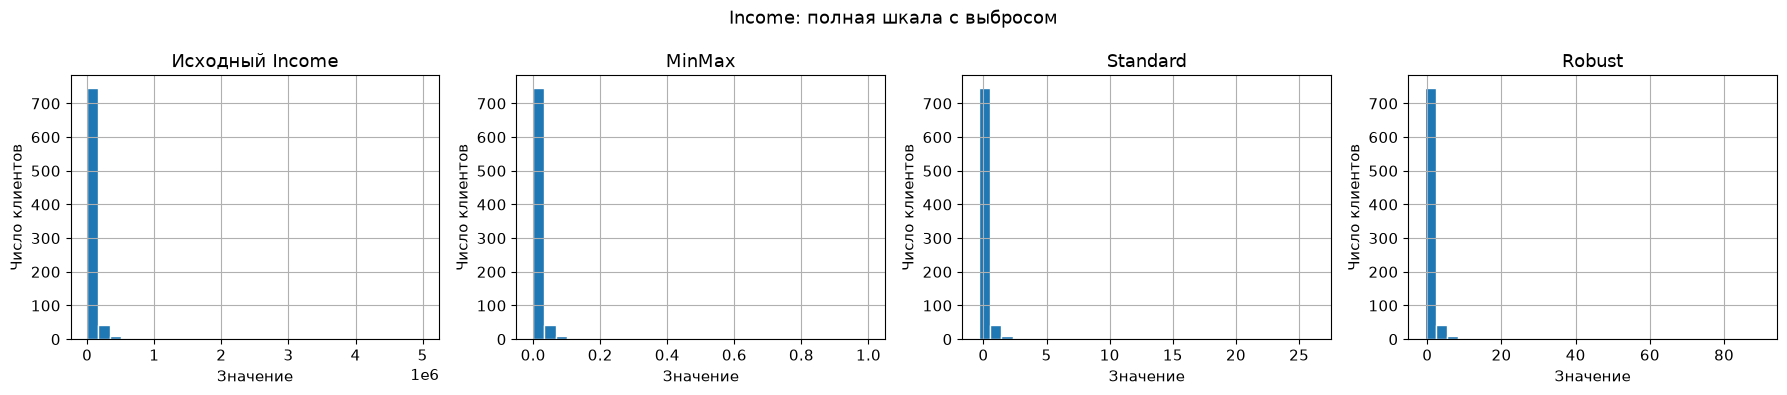

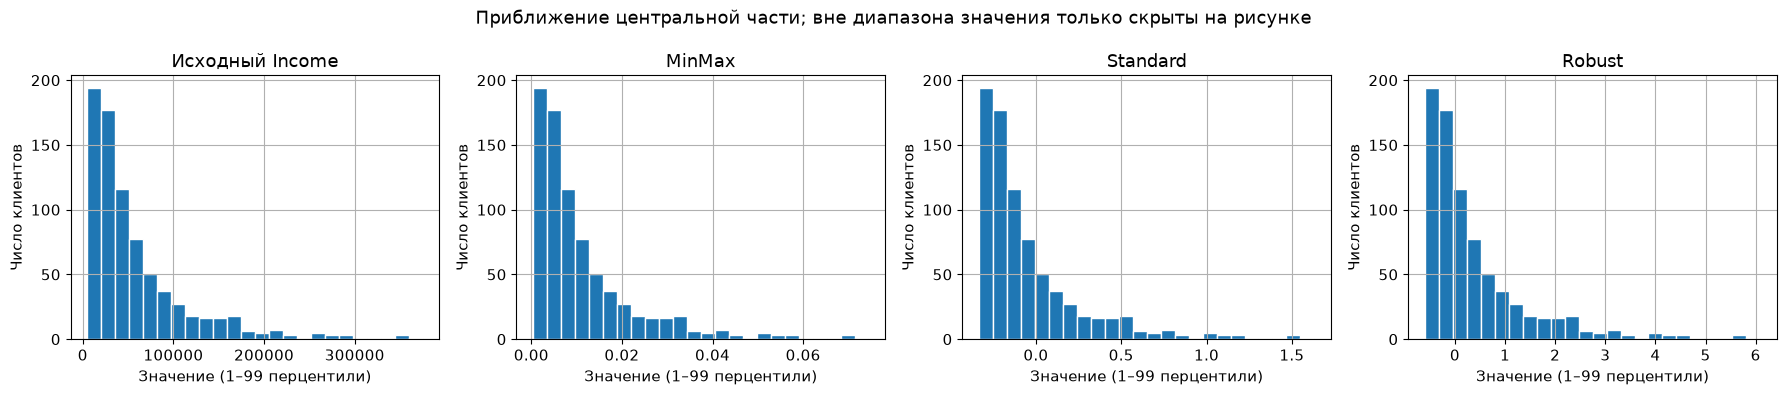

MinMax: доля значений ниже 0.05 = 0.97


In [8]:
income = df[['Income']]
scaled_income = {'Исходный Income': income.to_numpy().ravel()}
for name, scaler in [('MinMax', MinMaxScaler()), ('Standard', StandardScaler()), ('Robust', RobustScaler())]:
    scaled_income[name] = scaler.fit_transform(income).ravel()
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, values) in zip(axes, scaled_income.items()):
    ax.hist(values, bins=30, edgecolor='white')
    ax.set(title=name, xlabel='Значение', ylabel='Число клиентов')
fig.suptitle('Income: полная шкала с выбросом')
plt.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, values) in zip(axes, scaled_income.items()):
    low, high = np.quantile(values, [0.01, 0.99])
    ax.hist(values, bins=np.linspace(low, high, 25), edgecolor='white')
    ax.set(title=name, xlabel='Значение (1–99 перцентили)', ylabel='Число клиентов')
fig.suptitle('Приближение центральной части; вне диапазона значения только скрыты на рисунке')
plt.tight_layout()
plt.show()
plt.close(fig)
print('MinMax: доля значений ниже 0.05 =', np.mean(scaled_income['MinMax'] < 0.05))

**Ответы.** 1. Все три преобразования линейные: форма распределения и порядок значений сохраняются у всех, меняется шкала оси. Называть Robust «лучше сохранившим форму» некорректно.
2. Особенно наглядна проблема MinMax: максимум 5 млн сжимает большинство доходов в узкий участок около 0. Standard также чувствителен через среднее и σ.
3. Для учебного `Income` выбираю Robust; в продакшене дополнительно проверил бы природу экстремальных доходов и `log1p` на обучающей выборке. Это демонстрация скейлеров на всей таблице, её параметры не используются для модели: модель ниже обучает свои преобразования только на train.

### 3.2. Выбор скейлера для каждого признака

In [9]:
scaler_choice = {'Age': 'StandardScaler', 'Income': 'RobustScaler',
                 'Tenure': 'MinMaxScaler', 'CreditScore': 'StandardScaler'}
justification = {
    'Age': 'Нет сильных экстремумов; центрирование и единичная дисперсия удобны линейной модели.',
    'Income': 'Асимметрия и выброс: медиана и IQR устойчивее среднего и стандартного отклонения.',
    'Tenure': 'Ограниченный диапазон стажа; удобно перевести train в [0, 1].',
    'CreditScore': 'Сопоставимый масштаб с другими числовыми входами для регуляризованной модели.',
}
for column in numeric_cols:
    print(column, '→', scaler_choice[column], ':', justification[column])

Age → StandardScaler : Нет сильных экстремумов; центрирование и единичная дисперсия удобны линейной модели.
Income → RobustScaler : Асимметрия и выброс: медиана и IQR устойчивее среднего и стандартного отклонения.
Tenure → MinMaxScaler : Ограниченный диапазон стажа; удобно перевести train в [0, 1].
CreditScore → StandardScaler : Сопоставимый масштаб с другими числовыми входами для регуляризованной модели.


**Ответ.** Это обоснованный учебный выбор, а не универсальный победитель. StandardScaler не требует нормального распределения. MinMax гарантирует [0,1] для обучающих границ; новые значения за этими границами могут выйти за [0,1]. Для деревьев масштабирование обычно не обязательно.

### 4.1. Два кодирования Gender

In [10]:
le = LabelEncoder()
df['Gender_Label'] = le.fit_transform(df['Gender'])
df_ohe = pd.get_dummies(df['Gender'], prefix='Gender', dtype=int)
print('Соответствие:', dict(zip(le.classes_, le.transform(le.classes_))))
display(pd.concat([df[['Gender', 'Gender_Label']], df_ohe], axis=1).head())

Соответствие: {'F': np.int64(0), 'M': np.int64(1)}


,Gender,Gender_Label,Gender_F,Gender_M
0,M,1,0,1
1,M,1,0,1
2,M,1,0,1
3,F,0,1,0
4,M,1,0,1


**Ответ.** Для двух категорий один код 0/1 применим и к линейным моделям, и к деревьям: ложного порядка между тремя и более категориями здесь нет. Для многокатегориального номинального признака числовые коды создают искусственные расстояния и пороги; One-Hot обычно понятнее. `LabelEncoder` предназначен прежде всего для целевой переменной; здесь использован только для требуемой демонстрации, в конвейере входов используется OneHotEncoder.

### 4.2. Явный порядок Education

In [11]:
oe = OrdinalEncoder(categories=[edu_order])
df['Education_Ord'] = oe.fit_transform(df[['Education']]).ravel()
display(df[['Education', 'Education_Ord']].drop_duplicates().sort_values('Education_Ord'))
auto_oe = OrdinalEncoder().fit(df[['Education']])
print('Без явного порядка:', dict(zip(auto_oe.categories_[0], range(len(auto_oe.categories_[0])))))

,Education,Education_Ord
2,High School,0.0
3,Bachelor,1.0
0,Master,2.0
19,PhD,3.0


Без явного порядка: {'Bachelor': 0, 'High School': 1, 'Master': 2, 'PhD': 3}


**Ответ.** Явный порядок: High School=0, Bachelor=1, Master=2, PhD=3. Автоматический алфавитный: Bachelor=0, High School=1, Master=2, PhD=3. Значит, без `categories` начальные два уровня поменялись бы местами. Даже верный ordinal-код предполагает равные шаги для линейной модели; при сомнении можно проверять One-Hot.

### 4.3. Частотное кодирование City

In [12]:
freq_map = df['City'].value_counts()
df['City_Freq'] = df['City'].map(freq_map)
display(df[['City', 'City_Freq']].drop_duplicates().sort_values('City_Freq'))

,City,City_Freq
0,Ufa,115
16,Kazan,133
7,Moscow,135
1,Ekaterinburg,138
5,Novosibirsk,139
3,SPb,140


**Ответ.** Города с одинаковой частотой получат одинаковый код и станут неразличимыми. Это критично, если редкие города одинаково часты, но имеют разный отток. Код также зависит от состава выборки; для модели частоты нужно учить только на train и определить значение для нового города. Здесь код демонстрационный и исключён из X.

### 5.1. ColumnTransformer без утечки данных

In [13]:
X = df.drop(columns=['Churn', 'Gender_Label', 'Education_Ord', 'City_Freq'])
y = df['Churn']
assert set(X.columns) == original_cols
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

def make_preprocessor():
    return ColumnTransformer([
        ('standard', StandardScaler(), ['Age', 'CreditScore']),
        ('income', RobustScaler(), ['Income']),
        ('tenure', MinMaxScaler(), ['Tenure']),
        ('nominal', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), nominal_cols),
        ('education', OrdinalEncoder(categories=[edu_order], handle_unknown='use_encoded_value',
                                     unknown_value=-1), ordinal_cols),
    ], remainder='drop')

preprocessor = make_preprocessor()
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
assert X_train_prepared.shape == (600, 11) and X_test_prepared.shape == (200, 11)
assert np.isfinite(X_train_prepared).all() and np.isfinite(X_test_prepared).all()
assert set(X_train.index).isdisjoint(X_test.index)
print(X_train.shape, '→', X_train_prepared.shape)
print(X_test.shape, '→', X_test_prepared.shape)
print('Признаки:', feature_names.tolist())
for name, matrix, indices in [('train', X_train_prepared, X_train.index),
                              ('test', X_test_prepared, X_test.index)]:
    prepared = pd.DataFrame(matrix, index=indices, columns=feature_names)
    prepared.index.name = 'source_row'
    prepared.to_csv(DATA / f'prepared_{name}.csv')
display(pd.DataFrame(X_train_prepared, columns=feature_names).head())

(600, 7) → (600, 11)
(200, 7) → (200, 11)
Признаки: ['standard__Age', 'standard__CreditScore', 'income__Income', 'tenure__Tenure', 'nominal__Gender_M', 'nominal__City_Kazan', 'nominal__City_Moscow', 'nominal__City_Novosibirsk', 'nominal__City_SPb', 'nominal__City_Ufa', 'education__Education']


,standard__Age,standard__CreditScore,income__Income,tenure__Tenure,nominal__Gender_M,nominal__City_Kazan,nominal__City_Moscow,nominal__City_Novosibirsk,nominal__City_SPb,nominal__City_Ufa,education__Education
0,0.799775,0.292537,-0.543984,0.033898,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.919937,0.539253,-0.292899,0.118644,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,-0.401840,-1.301625,-0.215430,0.322034,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,0.799775,-0.612087,2.331972,0.593220,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,-1.483295,0.615165,0.135201,0.118644,0.0,0.0,1.0,0.0,0.0,0.0,1.0


**Ответы.** 1. `fit` узнаёт средние, масштабы и категории. Если он увидит test, оценка модели получит информацию из отложенных данных. Поэтому train: `fit_transform`, test: только `transform` теми же параметрами.
2. 11 столбцов = 2 Standard + 1 Income + 1 Tenure + 1 Gender + 5 City + 1 Education.
3. По умолчанию новый город вызывает ошибку. Здесь `handle_unknown='ignore'` преобразует его в нули в блоке города. При `drop='first'` это совпадает с базовой категорией: поведение допустимо для демонстрации, но в реальном сервисе нужен мониторинг новых категорий или выделенный `Other`. Код −1 для неизвестного образования также требует осмысленной обработки.

In [14]:
# Проверка поведения незнакомого города, без повторного fit.
unseen = X_test.iloc[[0]].copy()
unseen['City'] = 'UnknownCity'
with warnings.catch_warnings(record=True) as seen_warnings:
    unknown_prepared = preprocessor.transform(unseen)
city_mask = np.array(['nominal__City_' in name for name in feature_names])
assert np.all(unknown_prepared[:, city_mask] == 0)
print('Незнакомый город →', unknown_prepared[:, city_mask])

# Дополнительная проверка сигнала в Churn. Порог 0.5 задан заранее.
model = Pipeline([('preprocessor', make_preprocessor()),
                  ('classifier', LogisticRegression(max_iter=2000, random_state=42))])
model.fit(X_train, y_train)
clean_proba = model.predict_proba(X_test)[:, 1]
dummy = DummyClassifier(strategy='prior').fit(X_train, y_train)
print('ROC AUC модели:', round(roc_auc_score(y_test, clean_proba), 4))
print('ROC AUC базовой модели:', round(roc_auc_score(y_test, dummy.predict_proba(X_test)[:, 1]), 4))
print('Accuracy модели:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Незнакомый город → [[0. 0. 0. 0. 0.]]
ROC AUC модели: 0.6611
ROC AUC базовой модели: 0.5
Accuracy модели: 0.64


**Пояснение.** ROC AUC оценивает порядок вероятностей: 0.5 — нет различения, 1 — идеальное различение. Accuracy зависит от порога и доли классов. Модель и её порог не подбирались по test; один случайный split даёт только учебную оценку, не доказательство качества на реальных клиентах.

### 6.1. Простая случайная и стратифицированная выборки

In [15]:
def stratified_sample(frame, strat_col, n_total, random_state=42):
    if not isinstance(n_total, (int, np.integer)) or isinstance(n_total, bool):
        raise ValueError('Размер должен быть целым числом')
    if not 0 <= n_total <= len(frame):
        raise ValueError('Размер вне диапазона 0..len(frame)')
    if frame[strat_col].isna().any():
        raise ValueError('Сначала определить обработку пропусков страты')
    if n_total == 0:
        return frame.iloc[:0].copy()
    counts = frame[strat_col].value_counts(sort=False)
    exact = counts / len(frame) * n_total
    allocation = np.floor(exact).astype(int)
    # Метод наибольших остатков: сумма квот точно равна n_total.
    remaining = n_total - int(allocation.sum())
    order = np.argsort(-(exact - allocation).to_numpy(), kind='stable')
    allocation.iloc[order[:remaining]] += 1
    rng = np.random.default_rng(random_state)
    parts = [frame.loc[frame[strat_col].eq(group)].sample(
                n=int(size), random_state=int(rng.integers(0, 2**31 - 1)))
             for group, size in allocation.items()]
    return pd.concat(parts).sample(frac=1, random_state=random_state)

s_rand = df.sample(n=100, random_state=42)
s_strat = stratified_sample(df, 'Churn', 100)
assert len(s_strat) == 100 and s_strat.index.is_unique
assert len(stratified_sample(df, 'Churn', 0)) == 0
assert len(stratified_sample(df, 'Churn', len(df))) == len(df)
population_rate = df.Churn.mean()
sample_comparison = pd.DataFrame({
    'n': [len(df), len(s_rand), len(s_strat)],
    'churn_rate': [population_rate, s_rand.Churn.mean(), s_strat.Churn.mean()],
}, index=['Популяция', 'Случайная', 'Стратифицированная'])
sample_comparison['absolute_error'] = abs(sample_comparison.churn_rate - population_rate)
display(sample_comparison)
print('Ближе по доле Churn:', sample_comparison.loc[['Случайная', 'Стратифицированная'],
                                                   'absolute_error'].idxmin())

,n,churn_rate,absolute_error
Популяция,800,0.37125,0.00000
Случайная,100,0.32000,0.05125
Стратифицированная,100,0.37000,0.00125


Ближе по доле Churn: Стратифицированная


**Ответы.** Пропорциональная стратификация сохраняет долю Churn с точностью целочисленных квот; в данном опыте сравнение показано выше. Это не гарантирует представительность по доходу, возрасту и другим признакам. `Churn` можно использовать для создания сбалансированного разбиения, но нельзя оставлять во входах X: это готовый ответ, то есть утечка целевой переменной.

### 6.2. Размер выборки и устойчивость медианы

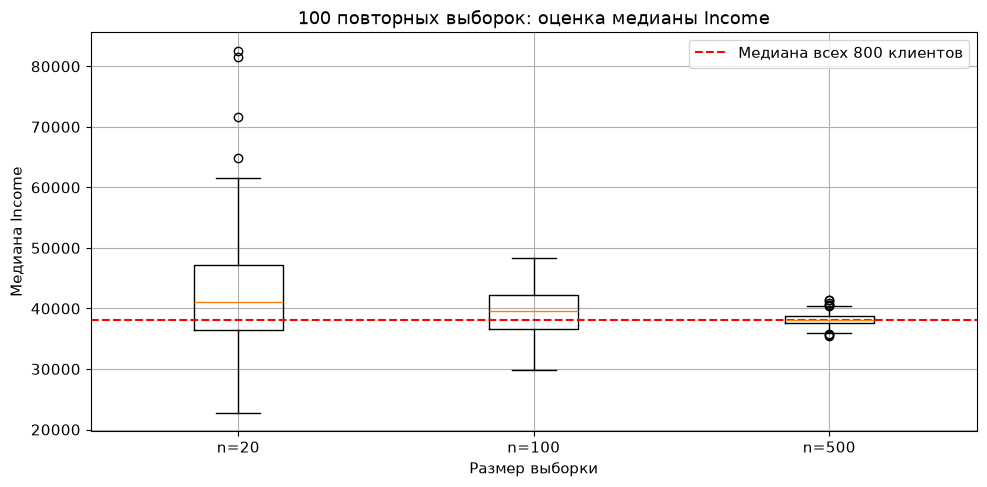

,n,std_median,std_mean,mean_of_medians
0,20,10391.28,35152.94,42278.40
1,100,3886.59,15520.87,39354.18
2,500,1138.21,5259.76,38188.22


In [16]:
sizes = [20, 100, 500]
results = {size: [] for size in sizes}
means = {size: [] for size in sizes}
for size in sizes:
    for seed in range(100):
        sample = df.sample(n=size, random_state=seed)['Income']
        results[size].append(sample.median())
        means[size].append(sample.mean())
fig, ax = plt.subplots()
ax.boxplot([results[size] for size in sizes], tick_labels=[f'n={size}' for size in sizes])
ax.axhline(df.Income.median(), color='red', linestyle='--', label='Медиана всех 800 клиентов')
ax.set(title='100 повторных выборок: оценка медианы Income', xlabel='Размер выборки', ylabel='Медиана Income')
ax.legend()
plt.tight_layout()
plt.show()
plt.close(fig)
sampling_summary = pd.DataFrame({
    'n': sizes,
    'std_median': [np.std(results[size], ddof=0) for size in sizes],
    'std_mean': [np.std(means[size], ddof=0) for size in sizes],
    'mean_of_medians': [np.mean(results[size]) for size in sizes],
})
display(sampling_summary.round(2))

**Ответ.** С ростом n оценки обычно становятся устойчивее; точные стандартные отклонения показаны в таблице. Правило 1/√n передаёт общий темп, но σ/√n — стандартная ошибка **среднего** независимых наблюдений, не точная формула для медианы. Для непрерывной плотности f около медианы m асимптотически SE медианы ≈ 1 / (2 f(m) √n).
Здесь выборка без возвращения из конечных 800 строк: при n=500 существенна дополнительная поправка конечной совокупности. Для среднего она равна √((N−n)/(N−1)) при σ с делителем N. Среднее чувствительнее к попаданию дохода 5 млн; медиана заметно устойчивее.

## Дополнение. Пропуски: обнаружение, механизм и сравнение обработки
В исходных данных пропусков нет. Для контролируемой проверки создаю отдельную копию X с искусственными пропусками; исходный CSV и целевая переменная не меняются.
- **MCAR**: вероятность скрыть Age постоянна и не зависит от данных.
- **MAR**: вероятность скрыть CreditScore зависит от наблюдаемого Tenure.
- **MNAR**: вероятность скрыть Income зависит от самого истинного дохода.
В реальной таблице по одной маске NaN нельзя надёжно установить MCAR/MAR/MNAR. Здесь механизм известен, потому что я сам его задал.

,missing_count,missing_pct
Age,73,9.12
Income,79,9.88
Tenure,0,0.00
CreditScore,65,8.12
Gender,0,0.00
Education,0,0.00
City,69,8.62


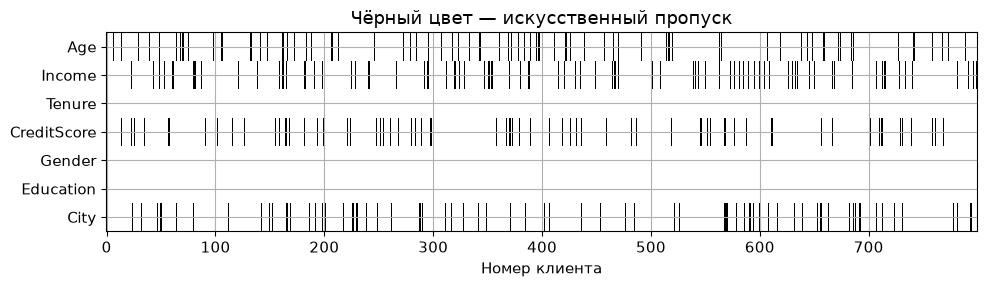

,method,train_n,test_n,test_coverage,roc_auc_common_complete_cases,roc_auc_available_test,income_fill_from_train,hidden_test_income_MAE
0,drop_rows,415,132,0.66,0.6467,0.6467,NaN,NaN
1,mean,600,200,1.00,0.6358,0.6274,64765.1349,83666.696
2,median,600,200,1.00,0.6366,0.6290,35875.0000,98336.250


Churn полного train: 0.3717 | после удаления строк: 0.3663


In [17]:
rng_missing = np.random.default_rng(2024)
X_missing = X.copy()
mask_age = rng_missing.random(len(X)) < 0.10
mask_score = rng_missing.random(len(X)) < np.where(X.Tenure < 12, 0.25, 0.04)
mask_income = rng_missing.random(len(X)) < np.where(X.Income > X.Income.quantile(0.8), 0.35, 0.05)
mask_city = rng_missing.random(len(X)) < 0.08
for column, mask in [('Age', mask_age), ('CreditScore', mask_score),
                     ('Income', mask_income), ('City', mask_city)]:
    X_missing.loc[mask, column] = np.nan
display(pd.DataFrame({'missing_count': X_missing.isna().sum(),
                      'missing_pct': X_missing.isna().mean() * 100}).round(2))
fig, ax = plt.subplots(figsize=(10, 3))
ax.imshow(X_missing.isna().T, aspect='auto', interpolation='nearest', cmap='Greys')
ax.set(yticks=range(len(X.columns)), yticklabels=X.columns,
       xlabel='Номер клиента', title='Чёрный цвет — искусственный пропуск')
plt.tight_layout()
plt.show()
plt.close(fig)

Xm_train = X_missing.loc[X_train.index]
Xm_test = X_missing.loc[X_test.index]
common_mask = Xm_test.notna().all(axis=1)
complete_train = Xm_train.notna().all(axis=1)
assert common_mask.sum() > 0 and y_test.loc[common_mask].nunique() == 2

def imputed_model(strategy):
    numeric = Pipeline([('imputer', SimpleImputer(strategy=strategy)),
                        ('scaler', StandardScaler())])
    categorical = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    ordinal = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                        ('encoder', OrdinalEncoder(categories=[edu_order]))])
    transform = ColumnTransformer([('numeric', numeric, numeric_cols),
                                   ('nominal', categorical, nominal_cols),
                                   ('education', ordinal, ordinal_cols)])
    return Pipeline([('preprocessor', transform),
                     ('classifier', LogisticRegression(max_iter=2000, random_state=42))])

comparison = []
for method in ['drop_rows', 'mean', 'median']:
    # Скейлеры и модель одинаковы; различается только удаление/заполнение.
    candidate = imputed_model('mean' if method == 'drop_rows' else method)
    train_mask = complete_train if method == 'drop_rows' else pd.Series(True, index=Xm_train.index)
    test_mask = common_mask if method == 'drop_rows' else pd.Series(True, index=Xm_test.index)
    candidate.fit(Xm_train.loc[train_mask], y_train.loc[train_mask])
    common_auc = roc_auc_score(y_test.loc[common_mask],
                              candidate.predict_proba(Xm_test.loc[common_mask])[:, 1])
    available_auc = roc_auc_score(y_test.loc[test_mask],
                                 candidate.predict_proba(Xm_test.loc[test_mask])[:, 1])
    hidden = Xm_test.Income.isna()
    income_mae = np.nan
    fill_value = np.nan
    if method != 'drop_rows':
        income_imputer = SimpleImputer(strategy=method).fit(Xm_train[['Income']])
        fill_value = income_imputer.statistics_[0]
        filled = income_imputer.transform(Xm_test[['Income']]).ravel()
        income_mae = mean_absolute_error(X_test.loc[hidden, 'Income'], filled[hidden.to_numpy()])
        assert np.isfinite(candidate.named_steps['preprocessor'].transform(Xm_test)).all()
    comparison.append({'method': method, 'train_n': int(train_mask.sum()),
                       'test_n': int(test_mask.sum()), 'test_coverage': test_mask.mean(),
                       'roc_auc_common_complete_cases': common_auc,
                       'roc_auc_available_test': available_auc,
                       'income_fill_from_train': fill_value,
                       'hidden_test_income_MAE': income_mae})
imputation_comparison = pd.DataFrame(comparison)
imputation_comparison.to_csv(DATA / 'imputation_comparison.csv', index=False)
display(imputation_comparison.round(4))
print('Churn полного train:', round(y_train.mean(), 4),
      '| после удаления строк:', round(y_train.loc[complete_train].mean(), 4))

**Вывод.** Удаление строк уменьшает обучающую выборку, меняет её состав и не даёт предсказания клиентам с NaN. Mean/median с модой для City сохраняют 100% тестовых клиентов; статистики заполнения получены только на train.
Сравнивать AUC удаления на сокращённом test с AUC заполнения на полном test напрямую некорректно: составы разные. Для честного общего сравнения приведён отдельный AUC на одних и тех же полных строках test; покрытие показано отдельно.

MAE восстановления дохода считается только по специально скрытым значениям test, истинные доходы доступны лишь для оценки эксперимента. Медиана устойчива к выбросам, но не обязана выиграть MAE при MNAR: скрытые доходы систематически выше. Простое заполнение не устраняет механизм MNAR и занижает вариативность. Один split и одна маска — демонстрация, а не устойчивый рейтинг методов. Метод по этому test не выбираю; для выбора нужна кросс-валидация на train.

## Итог
Выполнены SMART и критическая проверка MECE, разобраны четыре вида смещений. Сравнены три скейлера, три способа кодирования и собран ColumnTransformer на 11 признаков без утечки. Реализована пропорциональная стратификация с точной суммой квот и изучена устойчивость медианы. Дополнительно сопоставлены удаление строк и заполнение пропусков, качество восстановления, состав данных и покрытие модели.

Документация: [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html), [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html).